# Práctica 3: Machine Learning
**Alumno:** Diego Raymundo Hernández Alonso<br>
**Boleta:** 2022361124<br>
**Grupo:** 6CV2<br>
**Unidad de aprendizaje:** Inteligencia Artificial<br>
**Profesor:** Andrés García Floriano

Comparativa de seis clasificadores (Distancia Mínima, 1-NN, K-NN, Naïve Bayes, SVM y Perceptrón Multicapa) sobre dos conjuntos de datos, evaluados con Hold-Out 70/30 y Validación Cruzada K-Fold (k = 5).

## Fase 1: Conjuntos de datos y métodos de validación
### 1.1 Bibliotecas y parámetros generales

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler

# Parámetros generales de la práctica
SEMILLA = 74              # semilla fija para que los resultados se puedan repetir
PORCENTAJE_PRUEBA = 0.30  # Hold-Out 70/30
NUMERO_PLIEGUES = 5       # K-Fold con k = 5

### 1.2 Dataset sintético con ruido estructurado
Se generan 500 muestras de 3 clases con 6 rasgos: 4 rasgos informativos y 2 redundantes (combinaciones lineales de los informativos). Además, el 10% de las etiquetas se cambian al azar (`flip_y = 0.10`) para simular ruido.

In [2]:
X_sintetico, y_sintetico = make_classification(
    n_samples=500,          # número de muestras
    n_features=6,           # rasgos totales
    n_informative=4,        # rasgos que sí ayudan a separar las clases
    n_redundant=2,          # rasgos que son combinación de los informativos
    n_classes=3,            # número de clases
    n_clusters_per_class=1, # un grupo de puntos por clase
    flip_y=0.10,            # 10% de etiquetas cambiadas al azar (ruido)
    class_sep=1.0,          # qué tan separadas están las clases
    random_state=SEMILLA
)

print("Forma de X_sintetico:", X_sintetico.shape)
print("Muestras por clase:", np.bincount(y_sintetico))

Forma de X_sintetico: (500, 6)
Muestras por clase: [175 158 167]


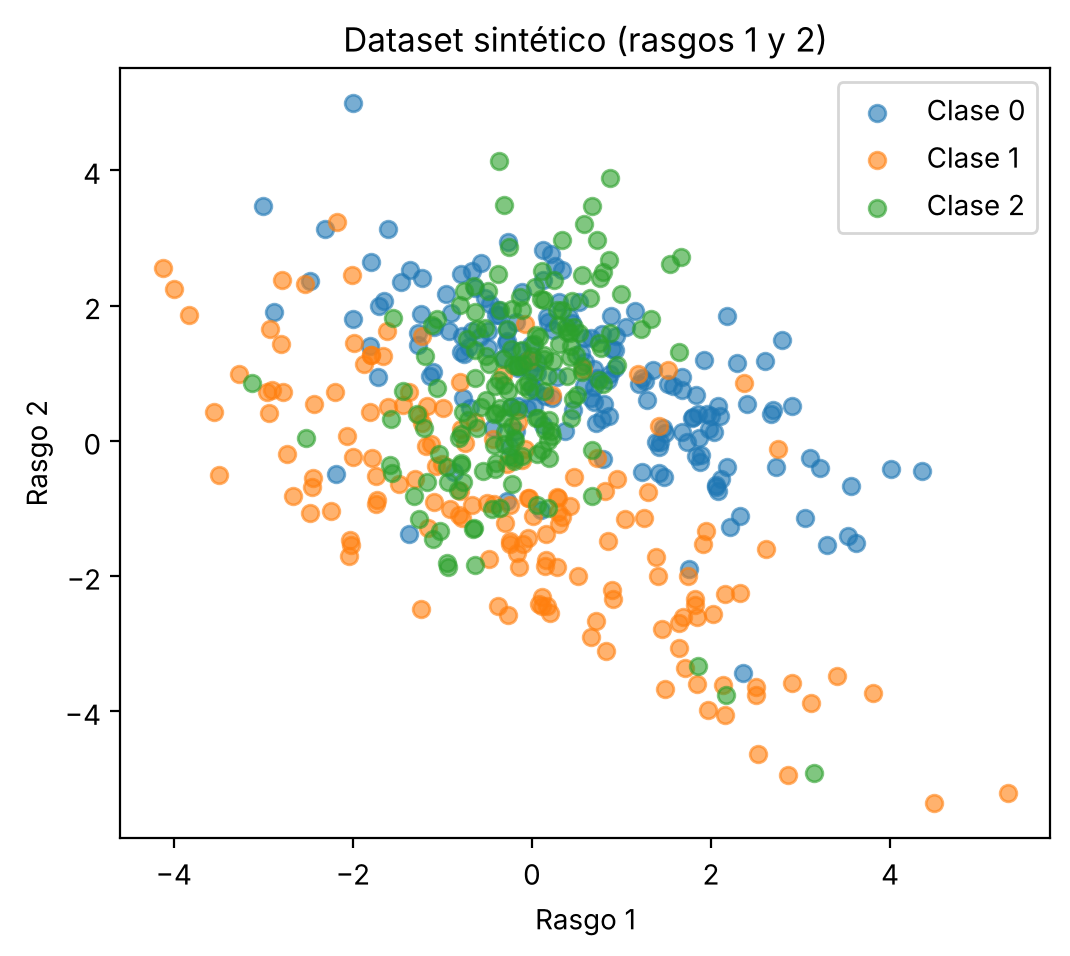

In [3]:
# Gráfica de los dos primeros rasgos para visualizar el traslape entre clases
plt.figure(figsize=(6, 5))
for clase in [0, 1, 2]:
    puntos_clase = X_sintetico[y_sintetico == clase]
    plt.scatter(puntos_clase[:, 0], puntos_clase[:, 1], label="Clase " + str(clase), alpha=0.6)
plt.xlabel("Rasgo 1")
plt.ylabel("Rasgo 2")
plt.title("Dataset sintético (rasgos 1 y 2)")
plt.legend()
plt.show()

### 1.3 Dataset de benchmark: Wine
178 vinos de 3 cultivos distintos, descritos por 13 rasgos químicos numéricos (alcohol, ácido málico, magnesio, prolina, etc.).

In [4]:
datos_wine = load_wine()
X_wine = datos_wine.data
y_wine = datos_wine.target
nombres_rasgos_wine = datos_wine.feature_names

print("Forma de X_wine:", X_wine.shape)
print("Muestras por clase:", np.bincount(y_wine))

# Rango de cada rasgo: muestra que las escalas son muy diferentes
tabla_rangos = pd.DataFrame({
    "Mínimo": X_wine.min(axis=0),
    "Máximo": X_wine.max(axis=0),
    "Promedio": X_wine.mean(axis=0)
}, index=nombres_rasgos_wine)
tabla_rangos.round(2)

Forma de X_wine: (178, 13)
Muestras por clase: [59 71 48]


,Mínimo,Máximo,Promedio
alcohol,11.03,14.83,13.00
malic_acid,0.74,5.80,2.34
ash,1.36,3.23,2.37
alcalinity_of_ash,10.60,30.00,19.49
magnesium,70.00,162.00,99.74
total_phenols,0.98,3.88,2.30
flavanoids,0.34,5.08,2.03
nonflavanoid_phenols,0.13,0.66,0.36
proanthocyanins,0.41,3.58,1.59
color_intensity,1.28,13.00,5.06


### 1.4 Normalización con StandardScaler
Cada rasgo se transforma con $z = \dfrac{x - \mu}{\sigma}$, donde $\mu$ y $\sigma$ se calculan **solo con los datos de entrenamiento**. Después, esos mismos valores se aplican a los datos de prueba. Así el modelo no "ve" información del conjunto de prueba (se evita la fuga de datos).

In [5]:
def escalar_datos(X_entrenamiento, X_prueba):
    escalador = StandardScaler()
    escalador.fit(X_entrenamiento)                     # calcula media y desviación con entrenamiento
    X_entrenamiento_escalado = escalador.transform(X_entrenamiento)
    X_prueba_escalado = escalador.transform(X_prueba)  # usa la media y desviación de entrenamiento
    return X_entrenamiento_escalado, X_prueba_escalado

### 1.5 Método de validación 1: Hold-Out 70/30
Se separa el 70% de los datos para entrenar y el 30% para probar. La partición es estratificada (`stratify`), es decir, conserva la proporción de cada clase en ambos conjuntos.

In [6]:
def particion_hold_out(X, y):
    X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
        X, y,
        test_size=PORCENTAJE_PRUEBA,
        stratify=y,
        random_state=SEMILLA
    )
    X_entrenamiento, X_prueba = escalar_datos(X_entrenamiento, X_prueba)
    return X_entrenamiento, X_prueba, y_entrenamiento, y_prueba


# Hold-Out para el dataset sintético
X_ent_sint, X_pru_sint, y_ent_sint, y_pru_sint = particion_hold_out(X_sintetico, y_sintetico)

# Hold-Out para el dataset Wine
X_ent_wine, X_pru_wine, y_ent_wine, y_pru_wine = particion_hold_out(X_wine, y_wine)

print("SINTÉTICO -> entrenamiento:", X_ent_sint.shape, "| prueba:", X_pru_sint.shape)
print("   clases en entrenamiento:", np.bincount(y_ent_sint), "| clases en prueba:", np.bincount(y_pru_sint))
print("WINE      -> entrenamiento:", X_ent_wine.shape, "| prueba:", X_pru_wine.shape)
print("   clases en entrenamiento:", np.bincount(y_ent_wine), "| clases en prueba:", np.bincount(y_pru_wine))

SINTÉTICO -> entrenamiento: (350, 6) | prueba: (150, 6)
   clases en entrenamiento: [122 111 117] | clases en prueba: [53 47 50]
WINE      -> entrenamiento: (124, 13) | prueba: (54, 13)
   clases en entrenamiento: [41 50 33] | clases en prueba: [18 21 15]


In [7]:
# Comprobación del escalado en Wine: después de escalar, cada rasgo de entrenamiento
# queda con promedio cercano a 0 y desviación estándar cercana a 1
tabla_escalado = pd.DataFrame({
    "Promedio antes": X_wine.mean(axis=0),
    "Desv. antes": X_wine.std(axis=0),
    "Promedio después": X_ent_wine.mean(axis=0),
    "Desv. después": X_ent_wine.std(axis=0)
}, index=nombres_rasgos_wine)
tabla_escalado.round(2)

,Promedio antes,Desv. antes,Promedio después,Desv. después
alcohol,13.00,0.81,0.0,1.0
malic_acid,2.34,1.11,-0.0,1.0
ash,2.37,0.27,0.0,1.0
alcalinity_of_ash,19.49,3.33,-0.0,1.0
magnesium,99.74,14.24,-0.0,1.0
total_phenols,2.30,0.62,0.0,1.0
flavanoids,2.03,1.00,-0.0,1.0
nonflavanoid_phenols,0.36,0.12,0.0,1.0
proanthocyanins,1.59,0.57,0.0,1.0
color_intensity,5.06,2.31,0.0,1.0


### 1.6 Método de validación 2: K-Fold Cross-Validation (k = 5)
Los datos se dividen en 5 partes (pliegues). En cada una de las 5 rondas, un pliegue distinto se usa como prueba y los otros 4 como entrenamiento. Se usa la versión estratificada para que cada pliegue tenga la misma proporción de clases. El escalado se repite dentro de cada ronda, usando solo los 4 pliegues de entrenamiento.

In [8]:
def particiones_k_fold(X, y):
    divisor = StratifiedKFold(n_splits=NUMERO_PLIEGUES, shuffle=True, random_state=SEMILLA)
    lista_particiones = []
    for indices_entrenamiento, indices_prueba in divisor.split(X, y):
        X_entrenamiento = X[indices_entrenamiento]
        X_prueba = X[indices_prueba]
        y_entrenamiento = y[indices_entrenamiento]
        y_prueba = y[indices_prueba]
        X_entrenamiento, X_prueba = escalar_datos(X_entrenamiento, X_prueba)
        lista_particiones.append((X_entrenamiento, X_prueba, y_entrenamiento, y_prueba))
    return lista_particiones


pliegues_sintetico = particiones_k_fold(X_sintetico, y_sintetico)
pliegues_wine = particiones_k_fold(X_wine, y_wine)

print("SINTÉTICO")
numero_ronda = 1
for X_ent, X_pru, y_ent, y_pru in pliegues_sintetico:
    print("  Ronda", numero_ronda, "-> entrenamiento:", len(y_ent), "| prueba:", len(y_pru), "| clases en prueba:", np.bincount(y_pru))
    numero_ronda = numero_ronda + 1

print("WINE")
numero_ronda = 1
for X_ent, X_pru, y_ent, y_pru in pliegues_wine:
    print("  Ronda", numero_ronda, "-> entrenamiento:", len(y_ent), "| prueba:", len(y_pru), "| clases en prueba:", np.bincount(y_pru))
    numero_ronda = numero_ronda + 1

SINTÉTICO
  Ronda 1 -> entrenamiento: 400 | prueba: 100 | clases en prueba: [35 32 33]
  Ronda 2 -> entrenamiento: 400 | prueba: 100 | clases en prueba: [35 32 33]
  Ronda 3 -> entrenamiento: 400 | prueba: 100 | clases en prueba: [35 32 33]
  Ronda 4 -> entrenamiento: 400 | prueba: 100 | clases en prueba: [35 31 34]
  Ronda 5 -> entrenamiento: 400 | prueba: 100 | clases en prueba: [35 31 34]
WINE
  Ronda 1 -> entrenamiento: 142 | prueba: 36 | clases en prueba: [12 14 10]
  Ronda 2 -> entrenamiento: 142 | prueba: 36 | clases en prueba: [12 14 10]
  Ronda 3 -> entrenamiento: 142 | prueba: 36 | clases en prueba: [12 14 10]
  Ronda 4 -> entrenamiento: 143 | prueba: 35 | clases en prueba: [12 14  9]
  Ronda 5 -> entrenamiento: 143 | prueba: 35 | clases en prueba: [11 15  9]


## Fase 2: Clasificadores programados desde cero
Los tres clasificadores de esta fase se programan solo con Python y NumPy, sin bibliotecas de Machine Learning. Todos usan la **distancia euclidiana** y tienen dos métodos:
- `fit(X, y)`: aprende a partir de los datos de entrenamiento.
- `predict(X)`: regresa la clase predicha para cada muestra nueva.

### 2.1 Funciones auxiliares

In [9]:
def distancia_euclidiana(punto_a, punto_b):
    # d = raíz( suma de (a_i - b_i)^2 )
    diferencias = punto_a - punto_b
    return np.sqrt(np.sum(diferencias ** 2))


def calcular_exactitud(y_real, y_predicha):
    # Exactitud (accuracy) = aciertos / total de muestras
    aciertos = 0
    for i in range(len(y_real)):
        if y_real[i] == y_predicha[i]:
            aciertos = aciertos + 1
    return aciertos / len(y_real)

### 2.2 Clasificador de Distancia Mínima
En el entrenamiento se calcula el **centroide** (punto promedio) de cada clase. Para clasificar una muestra nueva, se mide su distancia a cada centroide y se asigna la clase del centroide más cercano.

In [10]:
class ClasificadorDistanciaMinima:

    def fit(self, X_entrenamiento, y_entrenamiento):
        self.clases = np.unique(y_entrenamiento)
        self.centroides = []
        for clase in self.clases:
            muestras_de_la_clase = X_entrenamiento[y_entrenamiento == clase]
            centroide = muestras_de_la_clase.mean(axis=0)   # promedio de cada rasgo
            self.centroides.append(centroide)

    def predict(self, X_prueba):
        predicciones = []
        for muestra in X_prueba:
            distancias = []
            for centroide in self.centroides:
                distancias.append(distancia_euclidiana(muestra, centroide))
            posicion_minima = np.argmin(distancias)          # centroide más cercano
            predicciones.append(self.clases[posicion_minima])
        return np.array(predicciones)

### 2.3 Clasificador 1-NN (vecino más cercano)
En el entrenamiento solo se guardan los datos. Para clasificar una muestra nueva, se mide su distancia contra **todas** las muestras de entrenamiento y se asigna la clase de la más cercana.

In [11]:
class ClasificadorUnVecino:

    def fit(self, X_entrenamiento, y_entrenamiento):
        self.X_entrenamiento = X_entrenamiento
        self.y_entrenamiento = y_entrenamiento

    def predict(self, X_prueba):
        predicciones = []
        for muestra in X_prueba:
            distancias = []
            for muestra_entrenamiento in self.X_entrenamiento:
                distancias.append(distancia_euclidiana(muestra, muestra_entrenamiento))
            posicion_vecino = np.argmin(distancias)          # muestra más cercana
            predicciones.append(self.y_entrenamiento[posicion_vecino])
        return np.array(predicciones)

### 2.4 Clasificador K-NN (K vecinos más cercanos)
Igual que 1-NN, pero se toman los **K** vecinos más cercanos y cada uno vota por su clase. Gana la clase con más votos.

**Regla de desempate:** si dos o más clases empatan en votos, gana la clase del vecino más cercano entre las clases empatadas.

In [12]:
class ClasificadorKVecinos:

    def __init__(self, k=5):
        self.k = k

    def fit(self, X_entrenamiento, y_entrenamiento):
        self.X_entrenamiento = X_entrenamiento
        self.y_entrenamiento = y_entrenamiento
        self.clases = np.unique(y_entrenamiento)

    def predict(self, X_prueba):
        predicciones = []
        for muestra in X_prueba:
            # 1) Distancia contra todas las muestras de entrenamiento
            distancias = []
            for muestra_entrenamiento in self.X_entrenamiento:
                distancias.append(distancia_euclidiana(muestra, muestra_entrenamiento))

            # 2) Posiciones de los K vecinos más cercanos (ordenados de menor a mayor distancia)
            posiciones_ordenadas = np.argsort(distancias)
            posiciones_vecinos = posiciones_ordenadas[:self.k]
            clases_vecinos = self.y_entrenamiento[posiciones_vecinos]

            # 3) Conteo de votos por clase
            votos = []
            for clase in self.clases:
                votos.append(np.sum(clases_vecinos == clase))
            votos = np.array(votos)

            # 4) Clases con el mayor número de votos (puede haber empate)
            maximo_votos = np.max(votos)
            clases_ganadoras = self.clases[votos == maximo_votos]

            # 5) Desempate: se recorre a los vecinos del más cercano al más lejano
            #    y gana la primera clase que esté entre las empatadas
            for clase_vecino in clases_vecinos:
                if clase_vecino in clases_ganadoras:
                    predicciones.append(clase_vecino)
                    break
        return np.array(predicciones)

### 2.5 Prueba de los tres clasificadores con Hold-Out 70/30

In [13]:
K_INICIAL = 5

modelos_desde_cero = {
    "Distancia Mínima": ClasificadorDistanciaMinima(),
    "1-NN": ClasificadorUnVecino(),
    "K-NN (k=5)": ClasificadorKVecinos(k=K_INICIAL)
}

resultados_fase2 = []
for nombre_modelo, modelo in modelos_desde_cero.items():
    # Dataset sintético
    modelo.fit(X_ent_sint, y_ent_sint)
    prediccion_sint = modelo.predict(X_pru_sint)
    exactitud_sint = calcular_exactitud(y_pru_sint, prediccion_sint)

    # Dataset Wine
    modelo.fit(X_ent_wine, y_ent_wine)
    prediccion_wine = modelo.predict(X_pru_wine)
    exactitud_wine = calcular_exactitud(y_pru_wine, prediccion_wine)

    resultados_fase2.append([nombre_modelo, exactitud_sint, exactitud_wine])

tabla_fase2 = pd.DataFrame(resultados_fase2, columns=["Modelo", "Sintético (Hold-Out)", "Wine (Hold-Out)"])
tabla_fase2.round(4)

,Modelo,Sintético (Hold-Out),Wine (Hold-Out)
0,Distancia Mínima,0.8000,0.9815
1,1-NN,0.7733,0.9815
2,K-NN (k=5),0.8667,0.9815


### 2.6 Verificación contra scikit-learn
Para comprobar que la implementación es correcta, se comparan las predicciones con las de los clasificadores equivalentes de scikit-learn (`NearestCentroid` y `KNeighborsClassifier`). Si el porcentaje de coincidencia es 100%, los algoritmos programados funcionan igual.

In [14]:
from sklearn.neighbors import NearestCentroid, KNeighborsClassifier

pares_a_comparar = [
    ("Distancia Mínima", ClasificadorDistanciaMinima(), NearestCentroid()),
    ("1-NN", ClasificadorUnVecino(), KNeighborsClassifier(n_neighbors=1)),
    ("K-NN (k=5)", ClasificadorKVecinos(k=K_INICIAL), KNeighborsClassifier(n_neighbors=K_INICIAL))
]

for nombre, modelo_propio, modelo_sklearn in pares_a_comparar:
    # Dataset sintético
    modelo_propio.fit(X_ent_sint, y_ent_sint)
    modelo_sklearn.fit(X_ent_sint, y_ent_sint)
    coincidencia_sint = np.mean(modelo_propio.predict(X_pru_sint) == modelo_sklearn.predict(X_pru_sint))

    # Dataset Wine
    modelo_propio.fit(X_ent_wine, y_ent_wine)
    modelo_sklearn.fit(X_ent_wine, y_ent_wine)
    coincidencia_wine = np.mean(modelo_propio.predict(X_pru_wine) == modelo_sklearn.predict(X_pru_wine))

    print(nombre, "-> coincidencia con scikit-learn | Sintético:", round(coincidencia_sint * 100, 2), "% | Wine:", round(coincidencia_wine * 100, 2), "%")

Distancia Mínima -> coincidencia con scikit-learn | Sintético: 100.0 % | Wine: 100.0 %
1-NN -> coincidencia con scikit-learn | Sintético: 100.0 % | Wine: 100.0 %


K-NN (k=5) -> coincidencia con scikit-learn | Sintético: 100.0 % | Wine: 100.0 %


## Fase 3: Clasificadores con bibliotecas y comparativa base
Se agregan tres clasificadores de scikit-learn con sus parámetros por defecto:
- **Naïve Bayes** (`GaussianNB`)
- **Máquina de Soporte Vectorial** (`SVC`)
- **Perceptrón Multicapa** (`MLPClassifier`): con los 200 ciclos de entrenamiento por defecto la red no alcanzaba a converger, por lo que se aumentó `max_iter` a 3000. Se fija `random_state` para que los pesos iniciales, y por lo tanto los resultados, sean siempre los mismos.

### 3.1 Creación de los seis modelos

In [15]:
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier


def crear_modelos():
    # Regresa modelos nuevos (sin entrenar) cada vez que se llama
    modelos = {
        "Distancia Mínima": ClasificadorDistanciaMinima(),
        "1-NN": ClasificadorUnVecino(),
        "K-NN (k=5)": ClasificadorKVecinos(k=K_INICIAL),
        "Naïve Bayes": GaussianNB(),
        "SVM": SVC(),
        "MLP": MLPClassifier(max_iter=3000, random_state=SEMILLA)
    }
    return modelos

### 3.2 Funciones de evaluación
- **Hold-Out:** se entrena una vez con el 70% y se mide la exactitud con el 30%.
- **K-Fold:** se entrena y evalúa 5 veces (una por pliegue) y se reportan el promedio y la desviación estándar de las 5 exactitudes.

In [16]:
def evaluar_hold_out(modelo, X_entrenamiento, X_prueba, y_entrenamiento, y_prueba):
    modelo.fit(X_entrenamiento, y_entrenamiento)
    y_predicha = modelo.predict(X_prueba)
    return calcular_exactitud(y_prueba, y_predicha)


def evaluar_k_fold(nombre_modelo, lista_pliegues):
    exactitudes = []
    for X_entrenamiento, X_prueba, y_entrenamiento, y_prueba in lista_pliegues:
        modelo = crear_modelos()[nombre_modelo]   # modelo nuevo en cada ronda
        modelo.fit(X_entrenamiento, y_entrenamiento)
        y_predicha = modelo.predict(X_prueba)
        exactitudes.append(calcular_exactitud(y_prueba, y_predicha))
    return np.mean(exactitudes), np.std(exactitudes)

### 3.3 Entrenamiento y evaluación de los 6 modelos en ambos datasets

In [17]:
resultados_base = []

for nombre_modelo, modelo in crear_modelos().items():
    # Dataset sintético
    holdout_sint = evaluar_hold_out(modelo, X_ent_sint, X_pru_sint, y_ent_sint, y_pru_sint)
    promedio_sint, desviacion_sint = evaluar_k_fold(nombre_modelo, pliegues_sintetico)

    # Dataset Wine
    modelo = crear_modelos()[nombre_modelo]
    holdout_wine = evaluar_hold_out(modelo, X_ent_wine, X_pru_wine, y_ent_wine, y_pru_wine)
    promedio_wine, desviacion_wine = evaluar_k_fold(nombre_modelo, pliegues_wine)

    resultados_base.append([nombre_modelo,
                            holdout_sint, promedio_sint, desviacion_sint,
                            holdout_wine, promedio_wine, desviacion_wine])
    print("Listo:", nombre_modelo)

# Tabla con los valores numéricos (se usará en la Fase 4 para las gráficas)
tabla_base_numerica = pd.DataFrame(resultados_base, columns=[
    "Modelo",
    "Sint. Hold-Out", "Sint. K-Fold promedio", "Sint. K-Fold desviación",
    "Wine Hold-Out", "Wine K-Fold promedio", "Wine K-Fold desviación"
])

Listo: Distancia Mínima
Listo: 1-NN
Listo: K-NN (k=5)


Listo: Naïve Bayes
Listo: SVM


Listo: MLP


### 3.4 Tabla comparativa base (exactitud)

In [18]:
def formato_porcentaje(valor):
    return str(round(valor * 100, 2)) + "%"


def formato_promedio_desviacion(promedio, desviacion):
    return str(round(promedio * 100, 2)) + "% ± " + str(round(desviacion * 100, 2)) + "%"


filas_tabla = []
for fila in resultados_base:
    filas_tabla.append([
        fila[0],
        formato_porcentaje(fila[1]),
        formato_promedio_desviacion(fila[2], fila[3]),
        formato_porcentaje(fila[4]),
        formato_promedio_desviacion(fila[5], fila[6])
    ])

tabla_comparativa_base = pd.DataFrame(filas_tabla, columns=[
    "Modelo", "Sintético Hold-Out", "Sintético K-Fold (k=5)", "Wine Hold-Out", "Wine K-Fold (k=5)"
])
tabla_comparativa_base

,Modelo,Sintético Hold-Out,Sintético K-Fold (k=5),Wine Hold-Out,Wine K-Fold (k=5)
0,Distancia Mínima,80.0%,80.6% ± 3.38%,98.15%,96.67% ± 5.39%
1,1-NN,77.33%,81.0% ± 4.34%,98.15%,94.95% ± 2.07%
2,K-NN (k=5),86.67%,87.6% ± 2.87%,98.15%,94.41% ± 3.01%
3,Naïve Bayes,81.33%,82.2% ± 1.72%,98.15%,97.21% ± 3.04%
4,SVM,88.67%,88.6% ± 3.61%,98.15%,98.32% ± 2.23%
5,MLP,84.67%,87.6% ± 4.88%,100.0%,96.65% ± 2.72%


## Fase 4: Ajuste de parámetros y complejidad temporal
Se prueban valores distintos a los usados por defecto en tres modelos:

| Modelo | Parámetro | Valor original | Valores probados | Qué controla |
|---|---|---|---|---|
| K-NN | `k` | 5 | 3, 7, 11 | Cuántos vecinos votan |
| SVM | `C` | 1 | 0.1, 10, 100 | Qué tan estricto es el modelo con los errores de entrenamiento |
| MLP | neuronas en la capa oculta | 100 | 10, 50 | Capacidad de la red para aprender patrones |

Cada configuración se evalúa con Hold-Out 70/30 y con K-Fold (k = 5) en ambos datasets.

### 4.1 Funciones para crear y evaluar las configuraciones

In [19]:
def crear_modelo_ajustado(tipo_modelo, valor):
    if tipo_modelo == "K-NN":
        return ClasificadorKVecinos(k=valor)
    if tipo_modelo == "SVM":
        return SVC(C=valor)
    if tipo_modelo == "MLP":
        return MLPClassifier(hidden_layer_sizes=(valor,), max_iter=3000, random_state=SEMILLA)


def evaluar_configuracion_k_fold(tipo_modelo, valor, lista_pliegues):
    exactitudes = []
    for X_entrenamiento, X_prueba, y_entrenamiento, y_prueba in lista_pliegues:
        modelo = crear_modelo_ajustado(tipo_modelo, valor)   # modelo nuevo en cada ronda
        modelo.fit(X_entrenamiento, y_entrenamiento)
        y_predicha = modelo.predict(X_prueba)
        exactitudes.append(calcular_exactitud(y_prueba, y_predicha))
    return np.mean(exactitudes), np.std(exactitudes)


# (tipo de modelo, nombre del parámetro, valor original, valores a probar)
pruebas_parametros = [
    ("K-NN", "k", 5, [3, 7, 11]),
    ("SVM", "C", 1, [0.1, 10, 100]),
    ("MLP", "neuronas", 100, [10, 50])
]

### 4.2 Ejecución de las pruebas

In [20]:
resultados_ajuste = []

for tipo_modelo, nombre_parametro, valor_original, valores_nuevos in pruebas_parametros:
    todos_los_valores = [valor_original] + valores_nuevos
    for valor in todos_los_valores:
        # Dataset sintético
        modelo = crear_modelo_ajustado(tipo_modelo, valor)
        holdout_sint = evaluar_hold_out(modelo, X_ent_sint, X_pru_sint, y_ent_sint, y_pru_sint)
        promedio_sint, desviacion_sint = evaluar_configuracion_k_fold(tipo_modelo, valor, pliegues_sintetico)

        # Dataset Wine
        modelo = crear_modelo_ajustado(tipo_modelo, valor)
        holdout_wine = evaluar_hold_out(modelo, X_ent_wine, X_pru_wine, y_ent_wine, y_pru_wine)
        promedio_wine, desviacion_wine = evaluar_configuracion_k_fold(tipo_modelo, valor, pliegues_wine)

        if valor == valor_original:
            etiqueta = nombre_parametro + " = " + str(valor) + " (original)"
        else:
            etiqueta = nombre_parametro + " = " + str(valor)

        resultados_ajuste.append([tipo_modelo, etiqueta, valor, valor == valor_original,
                                  holdout_sint, promedio_sint, desviacion_sint,
                                  holdout_wine, promedio_wine, desviacion_wine])
    print("Listo:", tipo_modelo)

tabla_ajuste_numerica = pd.DataFrame(resultados_ajuste, columns=[
    "Modelo", "Configuración", "Valor", "Es original",
    "Sint. Hold-Out", "Sint. K-Fold promedio", "Sint. K-Fold desviación",
    "Wine Hold-Out", "Wine K-Fold promedio", "Wine K-Fold desviación"
])

Listo: K-NN
Listo: SVM


Listo: MLP


### 4.3 Tabla de resultados del ajuste de parámetros

In [21]:
filas_tabla_ajuste = []
for fila in resultados_ajuste:
    filas_tabla_ajuste.append([
        fila[0],
        fila[1],
        formato_porcentaje(fila[4]),
        formato_promedio_desviacion(fila[5], fila[6]),
        formato_porcentaje(fila[7]),
        formato_promedio_desviacion(fila[8], fila[9])
    ])

tabla_ajuste = pd.DataFrame(filas_tabla_ajuste, columns=[
    "Modelo", "Configuración", "Sintético Hold-Out", "Sintético K-Fold (k=5)", "Wine Hold-Out", "Wine K-Fold (k=5)"
])
tabla_ajuste

,Modelo,Configuración,Sintético Hold-Out,Sintético K-Fold (k=5),Wine Hold-Out,Wine K-Fold (k=5)
0,K-NN,k = 5 (original),86.67%,87.6% ± 2.87%,98.15%,94.41% ± 3.01%
1,K-NN,k = 3,85.33%,85.6% ± 3.44%,98.15%,93.84% ± 2.7%
2,K-NN,k = 7,87.33%,89.0% ± 3.58%,98.15%,94.98% ± 3.23%
3,K-NN,k = 11,86.0%,88.4% ± 4.32%,100.0%,96.1% ± 2.83%
4,SVM,C = 1 (original),88.67%,88.6% ± 3.61%,98.15%,98.32% ± 2.23%
5,SVM,C = 0.1,88.0%,87.0% ± 2.76%,98.15%,97.75% ± 1.13%
6,SVM,C = 10,88.67%,89.8% ± 4.62%,96.3%,97.76% ± 3.24%
7,SVM,C = 100,83.33%,87.6% ± 4.92%,96.3%,97.76% ± 3.24%
8,MLP,neuronas = 100 (original),84.67%,87.6% ± 4.88%,100.0%,96.65% ± 2.72%
9,MLP,neuronas = 10,89.33%,87.4% ± 3.61%,100.0%,97.76% ± 3.24%


In [22]:
# Mejor configuración de cada modelo en cada dataset (según el promedio de K-Fold)
filas_mejores = []
for tipo_modelo in ["K-NN", "SVM", "MLP"]:
    filas_modelo = tabla_ajuste_numerica[tabla_ajuste_numerica["Modelo"] == tipo_modelo]
    fila_original = filas_modelo[filas_modelo["Es original"] == True].iloc[0]

    for nombre_dataset, columna in [("Sintético", "Sint. K-Fold promedio"), ("Wine", "Wine K-Fold promedio")]:
        posicion_mejor = filas_modelo[columna].idxmax()
        fila_mejor = filas_modelo.loc[posicion_mejor]
        diferencia = fila_mejor[columna] - fila_original[columna]
        filas_mejores.append([tipo_modelo, nombre_dataset,
                              formato_porcentaje(fila_original[columna]),
                              fila_mejor["Configuración"],
                              formato_porcentaje(fila_mejor[columna]),
                              str(round(diferencia * 100, 2)) + " puntos"])

tabla_mejores = pd.DataFrame(filas_mejores, columns=[
    "Modelo", "Dataset", "K-Fold original", "Mejor configuración", "K-Fold mejor", "Mejora"
])
tabla_mejores

,Modelo,Dataset,K-Fold original,Mejor configuración,K-Fold mejor,Mejora
0,K-NN,Sintético,87.6%,k = 7,89.0%,1.4 puntos
1,K-NN,Wine,94.41%,k = 11,96.1%,1.68 puntos
2,SVM,Sintético,88.6%,C = 10,89.8%,1.2 puntos
3,SVM,Wine,98.32%,C = 1 (original),98.32%,0.0 puntos
4,MLP,Sintético,87.6%,neuronas = 50,88.8%,1.2 puntos
5,MLP,Wine,96.65%,neuronas = 10,97.76%,1.11 puntos


### 4.4 Gráficas
**Gráfica 1.** Exactitud promedio con K-Fold de los seis modelos (con sus parámetros originales) en ambos datasets. La línea negra sobre cada barra indica la desviación estándar entre los 5 pliegues.

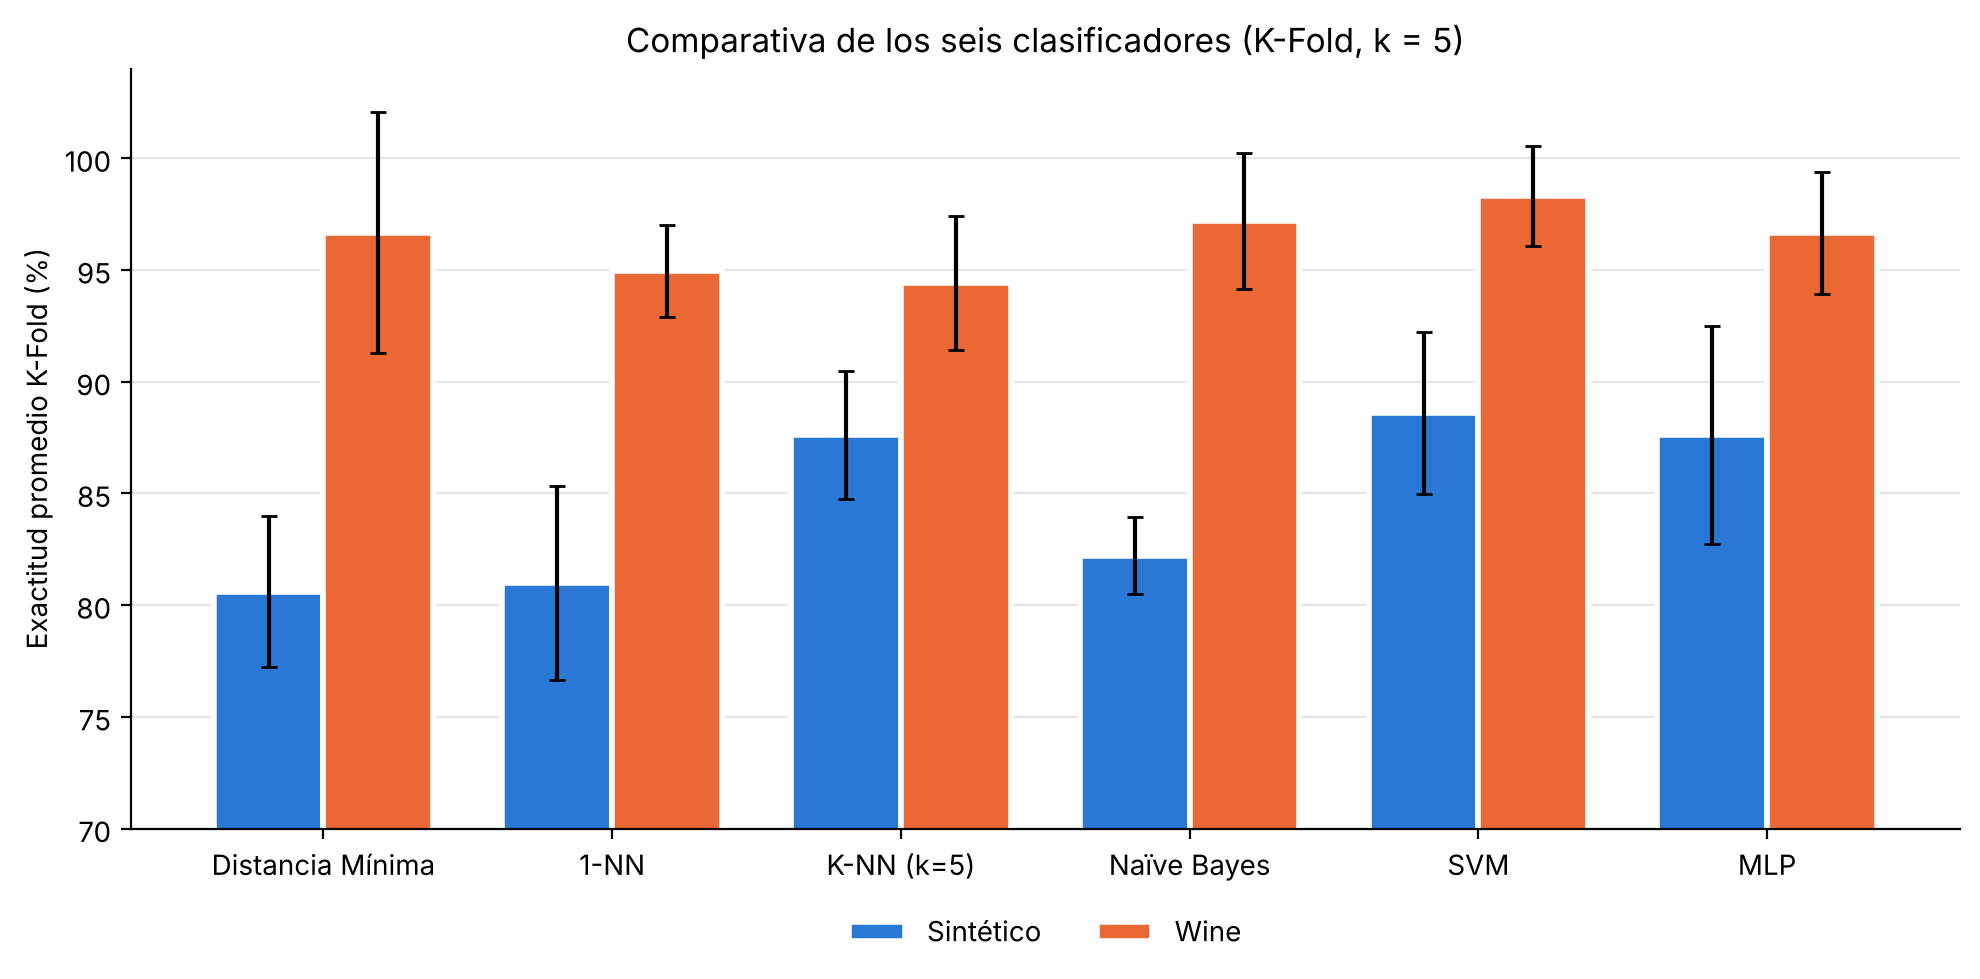

In [23]:
COLOR_SINTETICO = "#2a78d6"   # azul
COLOR_WINE = "#eb6834"        # naranja

nombres_modelos = list(tabla_base_numerica["Modelo"])
posiciones = np.arange(len(nombres_modelos))
ancho_barra = 0.38

figura, eje = plt.subplots(figsize=(10, 5))
eje.bar(posiciones - ancho_barra / 2, tabla_base_numerica["Sint. K-Fold promedio"] * 100, ancho_barra,
        yerr=tabla_base_numerica["Sint. K-Fold desviación"] * 100, capsize=3,
        color=COLOR_SINTETICO, label="Sintético", edgecolor="white", linewidth=2)
eje.bar(posiciones + ancho_barra / 2, tabla_base_numerica["Wine K-Fold promedio"] * 100, ancho_barra,
        yerr=tabla_base_numerica["Wine K-Fold desviación"] * 100, capsize=3,
        color=COLOR_WINE, label="Wine", edgecolor="white", linewidth=2)

eje.set_xticks(posiciones)
eje.set_xticklabels(nombres_modelos)
eje.set_ylabel("Exactitud promedio K-Fold (%)")
eje.set_ylim(70, 104)
eje.set_title("Comparativa de los seis clasificadores (K-Fold, k = 5)")
eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
eje.grid(axis="y", alpha=0.3)
eje.set_axisbelow(True)
eje.spines["top"].set_visible(False)
eje.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

**Gráfica 2.** Comparación entre la configuración original y la mejor configuración encontrada para K-NN, SVM y MLP.

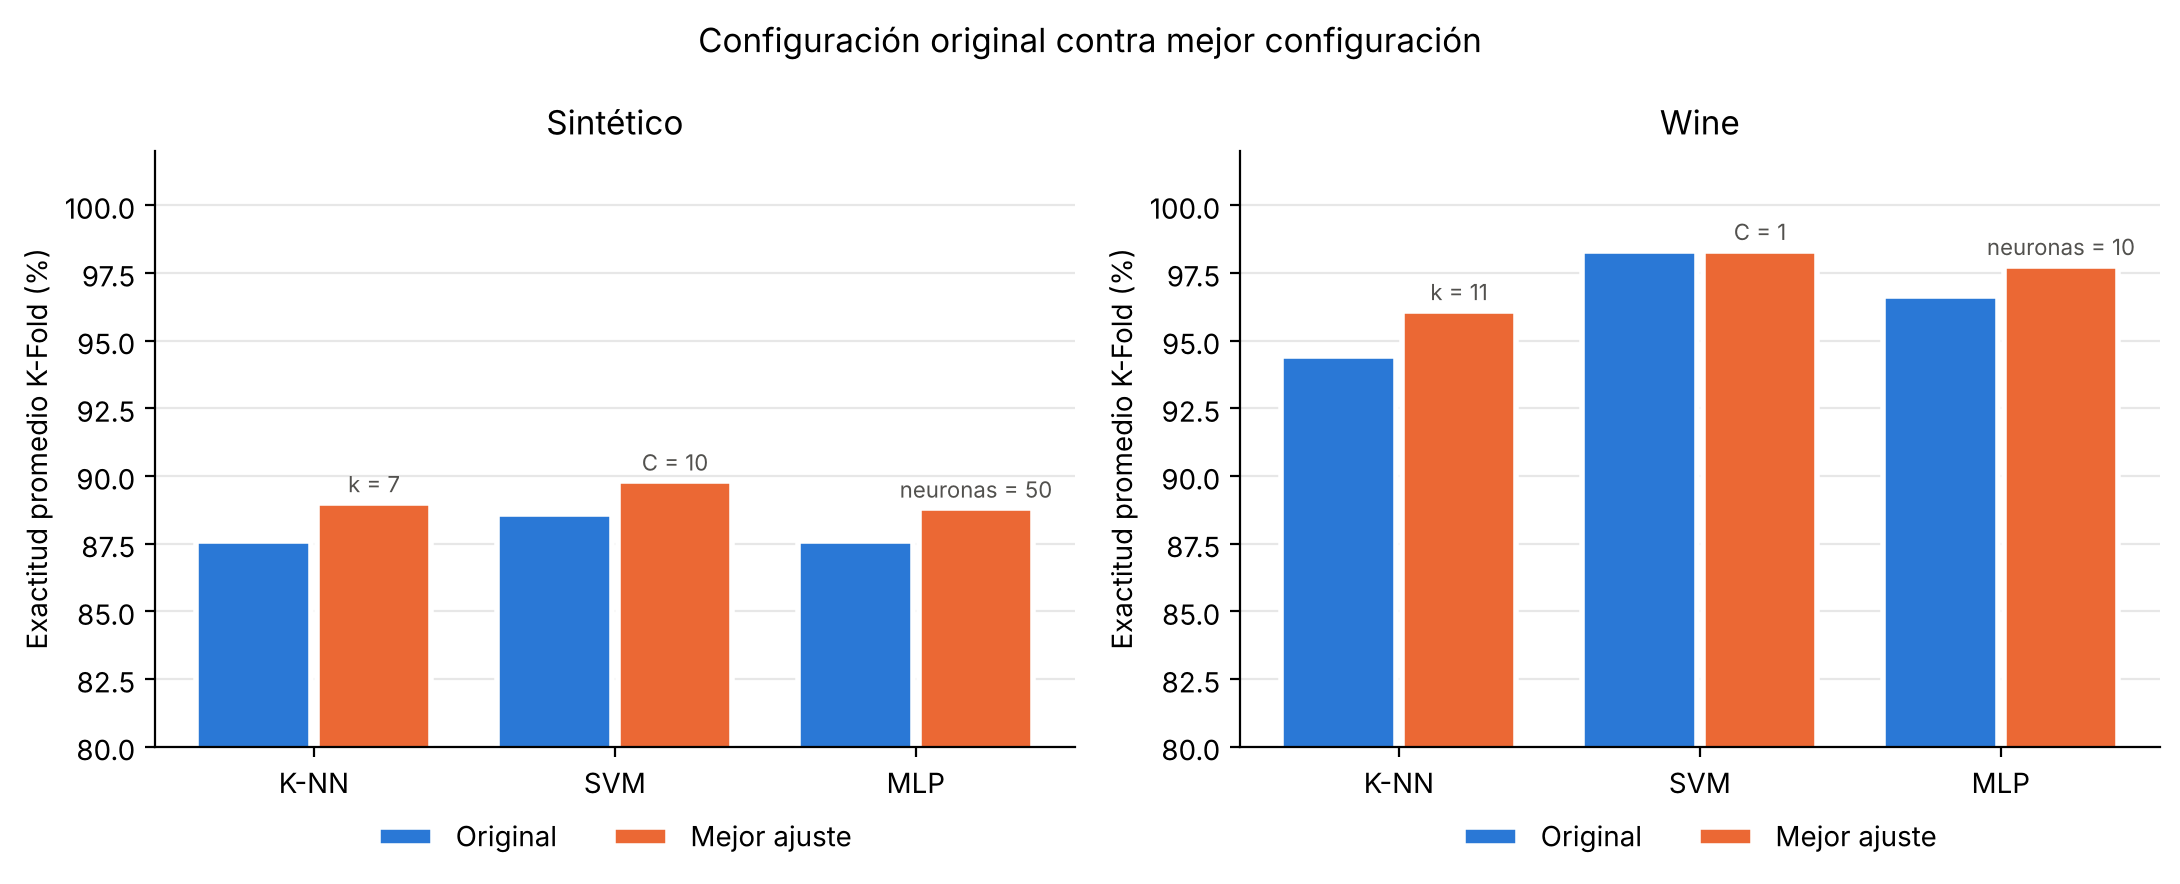

In [24]:
COLOR_ORIGINAL = "#2a78d6"   # azul
COLOR_MEJOR = "#eb6834"      # naranja

figura, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
datasets_grafica = [("Sintético", "Sint. K-Fold promedio"), ("Wine", "Wine K-Fold promedio")]

for numero_grafica in range(2):
    nombre_dataset, columna = datasets_grafica[numero_grafica]
    eje = ejes[numero_grafica]
    valores_originales = []
    valores_mejores = []
    etiquetas_mejores = []
    for tipo_modelo in ["K-NN", "SVM", "MLP"]:
        filas_modelo = tabla_ajuste_numerica[tabla_ajuste_numerica["Modelo"] == tipo_modelo]
        fila_original = filas_modelo[filas_modelo["Es original"] == True].iloc[0]
        fila_mejor = filas_modelo.loc[filas_modelo[columna].idxmax()]
        valores_originales.append(fila_original[columna] * 100)
        valores_mejores.append(fila_mejor[columna] * 100)
        etiquetas_mejores.append(fila_mejor["Configuración"].replace(" (original)", ""))

    posiciones = np.arange(3)
    eje.bar(posiciones - 0.2, valores_originales, 0.38, color=COLOR_ORIGINAL, label="Original",
            edgecolor="white", linewidth=2)
    barras_mejores = eje.bar(posiciones + 0.2, valores_mejores, 0.38, color=COLOR_MEJOR, label="Mejor ajuste",
                             edgecolor="white", linewidth=2)
    for i in range(3):
        eje.text(posiciones[i] + 0.2, valores_mejores[i] + 0.4, etiquetas_mejores[i],
                 ha="center", fontsize=8, color="#52514e")

    eje.set_xticks(posiciones)
    eje.set_xticklabels(["K-NN", "SVM", "MLP"])
    eje.set_ylim(80, 102)
    eje.set_ylabel("Exactitud promedio K-Fold (%)")
    eje.set_title(nombre_dataset)
    eje.grid(axis="y", alpha=0.3)
    eje.set_axisbelow(True)
    eje.spines["top"].set_visible(False)
    eje.spines["right"].set_visible(False)
    eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)

figura.suptitle("Configuración original contra mejor configuración")
plt.tight_layout()
plt.show()

**Gráfica 3.** Matrices de confusión del mejor clasificador general (SVM, con el mejor valor de `C` de cada dataset) sobre el conjunto de prueba del Hold-Out. Las filas son la clase real y las columnas la clase predicha: la diagonal son los aciertos y lo que queda fuera de ella son los errores.

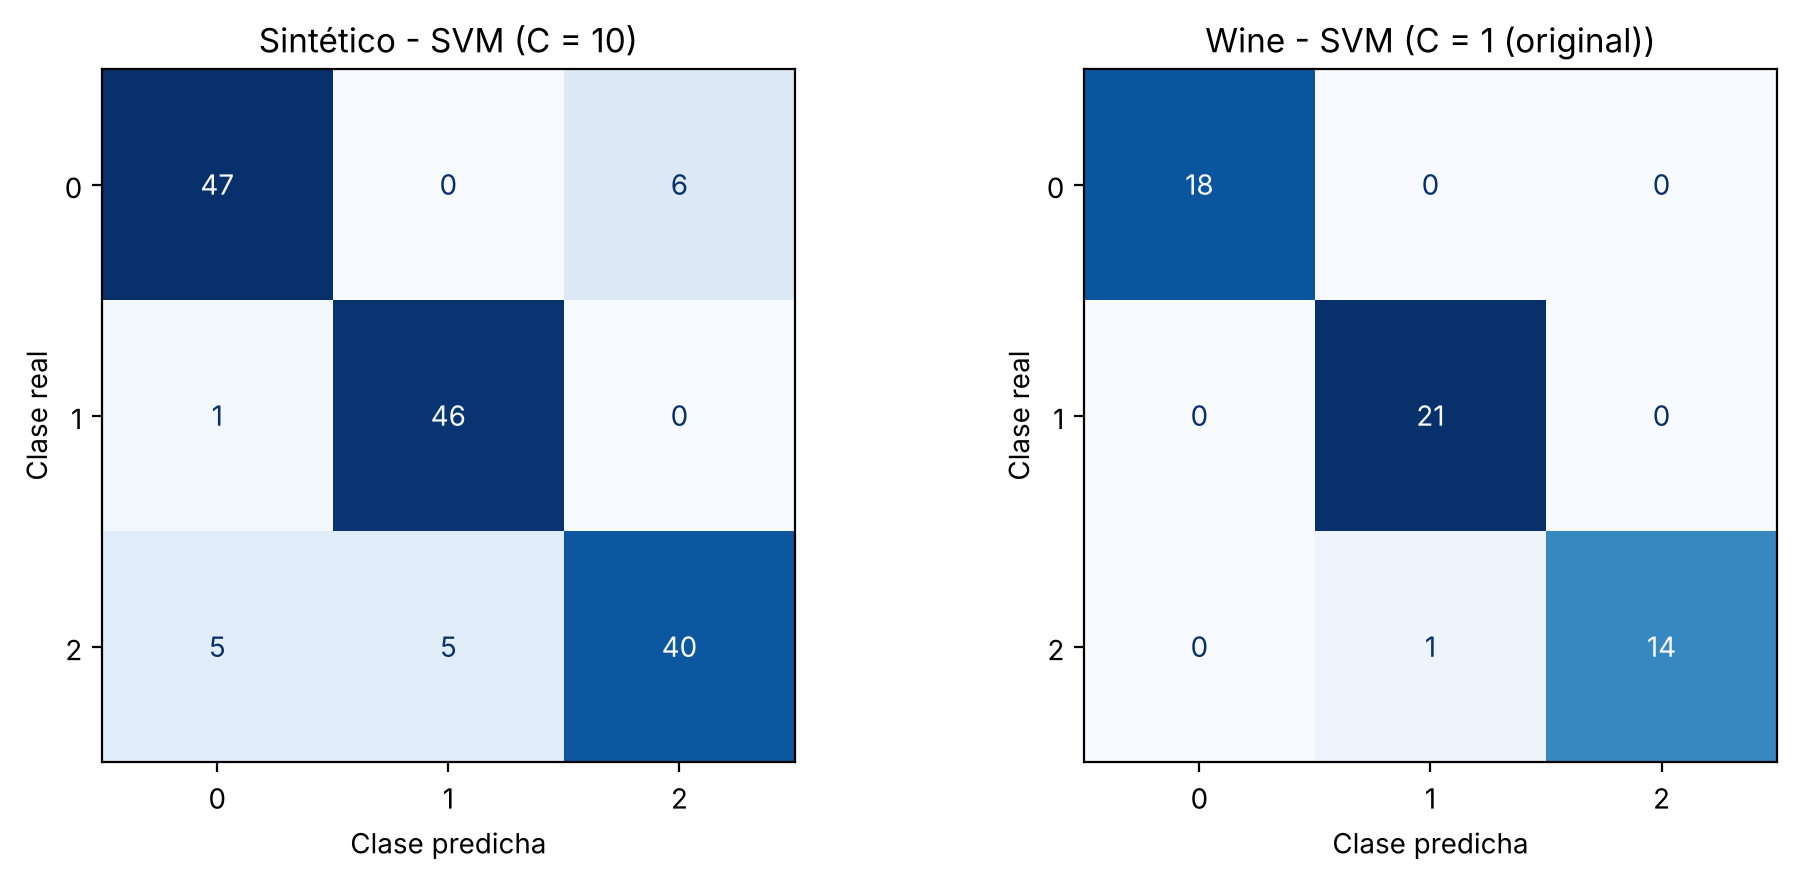

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

filas_svm = tabla_ajuste_numerica[tabla_ajuste_numerica["Modelo"] == "SVM"]
fila_mejor_sintetico = filas_svm.loc[filas_svm["Sint. K-Fold promedio"].idxmax()]
fila_mejor_wine = filas_svm.loc[filas_svm["Wine K-Fold promedio"].idxmax()]
mejor_c_sintetico = fila_mejor_sintetico["Valor"]
mejor_c_wine = fila_mejor_wine["Valor"]

svm_sintetico = SVC(C=mejor_c_sintetico)
svm_sintetico.fit(X_ent_sint, y_ent_sint)
matriz_sintetico = confusion_matrix(y_pru_sint, svm_sintetico.predict(X_pru_sint))

svm_wine = SVC(C=mejor_c_wine)
svm_wine.fit(X_ent_wine, y_ent_wine)
matriz_wine = confusion_matrix(y_pru_wine, svm_wine.predict(X_pru_wine))

figura, ejes = plt.subplots(1, 2, figsize=(10, 4.5))
ConfusionMatrixDisplay(matriz_sintetico).plot(ax=ejes[0], cmap="Blues", colorbar=False)
ejes[0].set_title("Sintético - SVM (" + fila_mejor_sintetico["Configuración"] + ")")
ejes[0].set_xlabel("Clase predicha")
ejes[0].set_ylabel("Clase real")

ConfusionMatrixDisplay(matriz_wine).plot(ax=ejes[1], cmap="Blues", colorbar=False)
ejes[1].set_title("Wine - SVM (" + fila_mejor_wine["Configuración"] + ")")
ejes[1].set_xlabel("Clase predicha")
ejes[1].set_ylabel("Clase real")

plt.tight_layout()
plt.show()

### 4.5 Preguntas

**¿Se mejoran los resultados al cambiar los parámetros?**

Sí, aunque de forma moderada. Según el promedio de K-Fold, en 5 de los 6 casos (3 modelos × 2 datasets) se encontró una configuración mejor que la original, con mejoras de entre 1.1 y 1.7 puntos porcentuales:

- **K-NN:** con `k = 7` el sintético sube de 87.6% a 89.0%, y con `k = 11` Wine sube de 94.41% a 96.1%. Más vecinos suavizan el efecto del ruido; en cambio, `k = 3` empeora el sintético (85.6%) porque la decisión depende de muy pocos puntos.
- **SVM:** con `C = 10` el sintético sube de 88.6% a 89.8%. En Wine el valor original `C = 1` ya era el mejor (98.32%). Los extremos empeoran: `C = 0.1` hace al modelo demasiado tolerante a los errores (subajuste) y `C = 100` lo hace demasiado estricto, por lo que se ajusta al ruido (sobreajuste) y su desviación entre pliegues aumenta.
- **MLP:** con 50 neuronas el sintético sube de 87.6% a 88.8%, y con 10 neuronas Wine sube de 96.65% a 97.76%. Una red más pequeña tiene menos capacidad de memorizar el ruido y generaliza mejor en datasets pequeños.

Hay dos observaciones importantes. Primero, las mejoras son menores que la desviación estándar entre pliegues (entre 2% y 5%), por lo que no se puede afirmar con seguridad que una configuración sea superior a la otra. Segundo, Hold-Out y K-Fold no siempre coinciden: por ejemplo, el MLP con 10 neuronas obtiene el mejor Hold-Out en el sintético (89.33%) pero no el mejor K-Fold (87.4%). Por esto la selección se hizo con K-Fold, que es más confiable que una sola partición.

**¿Cómo se podrían encontrar los mejores parámetros para cada dataset?**

1. **Búsqueda en rejilla (Grid Search) con validación cruzada:** se define una lista de valores candidatos para cada parámetro (por ejemplo, `k` impares de 1 a 21, o `C` en escala logarítmica: 0.01, 0.1, 1, 10, 100), se evalúa cada combinación con K-Fold y se elige la de mayor exactitud promedio. En scikit-learn esto se hace con `GridSearchCV`.
2. **Búsqueda aleatoria (Random Search):** cuando hay muchos parámetros, en lugar de probar todas las combinaciones se prueban combinaciones elegidas al azar, lo que reduce el tiempo de cómputo (`RandomizedSearchCV`).
3. **Separar la selección de la evaluación final:** los parámetros deben elegirse usando solo los datos de entrenamiento (con K-Fold dentro de ellos), y el conjunto de prueba debe usarse una única vez al final. Si se usan los mismos datos para elegir y para reportar, el resultado es ligeramente optimista.

Los resultados muestran que la búsqueda debe hacerse **por separado para cada dataset**: el mejor `k` fue 7 para el sintético y 11 para Wine, y el mejor `C` fue 10 para el sintético y 1 para Wine. No existe una configuración que sea la mejor para todos los problemas.

### 4.6 Análisis de complejidad temporal

Notación: $n$ = muestras de entrenamiento, $m$ = muestras a clasificar, $d$ = número de rasgos, $c$ = número de clases, $k$ = vecinos, $s$ = vectores de soporte, $h$ = neuronas en la capa oculta, $e$ = épocas (iteraciones) de entrenamiento.

| Clasificador | Entrenamiento | Predicción ($m$ muestras) | Justificación |
|---|---|---|---|
| Distancia Mínima | $O(n \cdot d)$ | $O(m \cdot c \cdot d)$ | Entrenar es promediar cada rasgo por clase; predecir es medir la distancia a $c$ centroides. |
| 1-NN | $O(1)$ | $O(m \cdot n \cdot d)$ | Solo guarda los datos; cada predicción calcula $n$ distancias de $d$ rasgos. |
| K-NN | $O(1)$ | $O(m \cdot (n \cdot d + n \log n))$ | Igual que 1-NN, más el ordenamiento de las $n$ distancias (`np.argsort`) para tomar los $k$ más cercanos. |
| Naïve Bayes | $O(n \cdot d)$ | $O(m \cdot c \cdot d)$ | Entrenar es calcular media y varianza de cada rasgo por clase; predecir es evaluar $c$ productos de $d$ probabilidades. |
| SVM | entre $O(n^2 \cdot d)$ y $O(n^3 \cdot d)$ | $O(m \cdot s \cdot d)$ | El entrenamiento resuelve un problema de optimización que compara pares de muestras; la predicción solo usa los $s$ vectores de soporte. |
| MLP | $O(e \cdot n \cdot (d \cdot h + h \cdot c))$ | $O(m \cdot (d \cdot h + h \cdot c))$ | Cada época recorre las $n$ muestras haciendo multiplicaciones de matrices hacia adelante y hacia atrás (retropropagación). |

**Análisis:**
- **Distancia Mínima y Naïve Bayes** son los más eficientes en ambas etapas: resumen cada clase en unos pocos valores (centroides, o medias y varianzas), así que predecir no depende de $n$.
- **1-NN y K-NN** son métodos "perezosos": no tienen costo de entrenamiento, pero todo el trabajo se hace al predecir, y crece con el tamaño del conjunto de entrenamiento. Con millones de muestras serían los más lentos al clasificar.
- **SVM y MLP** son los más costosos de entrenar (SVM por su crecimiento cuadrático o cúbico con $n$, y MLP por las $e$ épocas, que en esta práctica llegaron a ser hasta 3000), pero una vez entrenados predicen rápido, porque su costo no depende de $n$ sino de $s$ o de $h$.
- En esta práctica se observa el compromiso entre costo y exactitud: los modelos más costosos de entrenar (SVM y MLP) fueron también los más exactos en el dataset con ruido.